# Customer Churn Analysis

## 1. Project Overview

### Project Objective

The objective of this project is to analyze customer data to understand churn patterns, identify customer segments, and discover factors associated with customer churn. The analysis aims to provide insights that may help businesses improve customer retention.

### Tools and Technologies

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Jupyter Notebook


### Project Workflow

1. Load the dataset
2. Perform initial data exploration
3. Assess data quality
4. Clean the dataset
5. Perform feature engineering
6. Validate the cleaned data
7. Conduct exploratory data analysis
8. Create data visualizations
9. Summarize key findings


In [1]:
# Import lilbraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Import data

df = pd.read_csv("data/customer_churn_messy.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (5280, 22)


,RowID,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn
0,1,CUST-14446,James Williams,69,Unknown,NaN,643-304-7944,james_williams@outlook.com,06-23-17,2,...,NaN,147.06,294.12,No,yes,True,NaN,4,11.0,Churned
1,2,CUST-14140,Barbara Brown,71,male,N.Y.,+16856031546,barbara_brown@outlook.com,05-07-15,15,...,FIBER OPTIC,90.14,1352.1,Yes,yes,yes,1,9,NaN,yes
2,3,CUST-13708,Sandra Johnson,18,Male,NY,123-456,sandra.johnson@hotmail.com,2015-06-19,102,...,dsl,52.46,5350.92,Yes,NaN,Y,True,14,NaN,0
3,4,CUST-11011,Susan Thomas,31,NaN,Florida,NaN,susanthomas@hotmail.com,07/08/2019,55,...,DSL,44.86,2467.3,0,no,False,1,1,5.0,No
4,5,CUST-10723,Yuki Garcia,74,M,TX,563-969-1540,yuki.garcia@yahoo.com,NaN,52,...,FIBER OPTIC,23.98,1246.96,1,0,Yes,1,1,NaN,Yes


In [3]:
df.info()
display(df.describe(include="all"))
display(df.isna().sum().sort_values(ascending=False))
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5280 entries, 0 to 5279
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   RowID              5280 non-null   int64  
 1   CustomerID         5270 non-null   object 
 2   Name               5226 non-null   object 
 3   Age                5136 non-null   object 
 4   Gender             4230 non-null   object 
 5   State              4691 non-null   object 
 6   Phone              3797 non-null   object 
 7   Email              5270 non-null   object 
 8   SignupDate         5163 non-null   object 
 9   TenureMonths       5167 non-null   object 
 10  Contract           4358 non-null   object 
 11  PaymentMethod      4790 non-null   object 
 12  InternetService    3522 non-null   object 
 13  MonthlyCharges     5132 non-null   object 
 14  TotalCharges       4676 non-null   object 
 15  SeniorCitizen      4015 non-null   object 
 16  Partner            4347 

,RowID,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn
count,5280.000000,5270,5226,5136,4230,4691,3797,5270,5163,5167,...,3522,5132,4676,4015,4347,4429,4431,5079,3748.000000,4260
unique,NaN,5000,1557,74,8,35,2862,4997,4228,126,...,6,4016,4199,4,10,10,10,19,NaN,8
top,NaN,CUST-12702,William Hernandez,28,male,Tx.,123-456,johndavis@yahoo.com,31/04/2021,48,...,dsl,?,,0,1,Y,0,8,NaN,No
freq,NaN,3,11,98,556,289,786,3,45,65,...,613,32,149,1364,480,469,468,349,NaN,562
mean,2640.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.453842,NaN
std,1524.349041,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.741480,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.000000,NaN
25%,1320.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN
50%,2640.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN
75%,3960.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,NaN


InternetService      1758
SatisfactionScore    1532
Phone                1483
SeniorCitizen        1265
Gender               1050
Churn                1020
Partner               933
Contract              922
Dependents            851
PaperlessBilling      849
TotalCharges          604
State                 589
PaymentMethod         490
NumSupportCalls       201
MonthlyCharges        148
Age                   144
SignupDate            117
TenureMonths          113
Name                   54
CustomerID             10
Email                  10
RowID                   0
dtype: int64

Duplicate rows: 0


In [4]:
# Delete RowID

df.drop(columns=['RowID'], inplace=True)

In [5]:
df[df.duplicated(keep=False)]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn
32,CUST-11217,Sarah Thomas,49,M,FL,NaN,sarah_thomas29@hotmail.com,26-09-2019,37,M2M,...,DSL,26.12,966.44,1,Yes,No,False,7,4.0,Active
38,CUST-10220,Mark Wilson,74,Other,California,123-456,markwilson22@company.co,09/12/2023,68,NaN,...,NaN,129.65,NaN,No,True,yes,Yes,9,2.0,Yes
49,CUST-13671,Christopher Martin,72,F,Fla.,+18074581668,christopher.martin8@yahoo.com,11-11-2020,118,Two year,...,NaN,47.06,5553.08,0,NaN,0,0,NaN,1.0,NaN
55,CUST-14701,Fatima Smith,85,female,CA,8938456008,fatima_smith@company.co,07/23/2015,115,Two year,...,dsl,48.75,5606.25,1,yes,False,No,2,5.0,Active
56,CUST-14590,Sandra Taylor,67,Other,NaN,123-456,sandra.taylor@gmail.com,06-14-19,11,Month-to-month,...,NaN,113.46,1248.06,NaN,NaN,True,yes,12,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5222,CUST-10201,Robert Wilson,70,M,Tx.,NaN,robert.wilson@company.co,2017/11/16,-,Monthly,...,NaN,101.67,4168.47,Yes,yes,Yes,Y,15,2.0,0
5223,CUST-11866,Jennifer Wilson,68,female,Calif.,123-456,jenniferwilson84@gmail.com,04-27-21,51,2 year,...,FIBER OPTIC,141.55,7219.05,0,Yes,Y,yes,10,2.0,NaN
5227,CUST-13830,Matthew Sanchez,73,Female,Calif.,2371180611,matthew_sanchez@hotmail.com,19/11/2016,47,Two Year,...,NaN,44.87,2108.89,NaN,Yes,0,NaN,15,11.0,Active
5243,CUST-11514,Thomas Lee,63,F,Calif.,8158775952,thomaslee@hotmail.com,01/13/2017,68,One year,...,FIBER OPTIC,17.46,1187.28,1,Yes,no,NaN,11,NaN,NaN


In [6]:
# Delete duplicated rows

df.drop_duplicates(inplace=True)

In [7]:
df[df['CustomerID'].duplicated(keep=False)].sort_values('CustomerID')

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn
510,CUST-10055,Yuki Lee,38,male,unknown,NaN,yukilee@yahoo.com,28-08-2021,62,Month-to-month,...,FIBER OPTIC,95.72,5934.64,0,NaN,0,Y,5,NaN,yes
1488,CUST-10055,YUKI LEE,38,male,unknown,NaN,YUKILEE@YAHOO.COM,28-08-2021,62,Month-to-month,...,FIBER OPTIC,95.72,5934.64,0,NaN,0,Y,5,NaN,yes
767,CUST-10073,Rahul Thomas,59,Other,NY,NaN,RAHUL.THOMAS73@HOTMAIL.COM,2019-02-04,69,Month-to-month,...,NaN,15.75,1086.75,1,1,True,0,13,-2.0,Active
2856,CUST-10073,Rahul Thomas,59,Other,NY,NaN,rahul.thomas73@hotmail.com,2019-02-04,69,Month-to-month,...,NaN,15.75,1086.75,1,1,True,0,13,-2.0,Active
550,CUST-10138,CHARLES ANDERSON,18,NaN,NaN,123-456,CHARLES_ANDERSON@HOTMAIL.COM,26/11/2019,82,Monthly,...,NaN,109.91,9012.62,Yes,Y,True,False,5,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1711,CUST-14759,Michael Johnson,64,Male,NY,(644) 819-6027,michael.johnson@outlook.com,"September 25, 2024",48,Monthly,...,NaN,77.2,3705.6,NaN,Y,NaN,NaN,1,NaN,NaN
2588,CUST-14841,Ahmed Davis,67,Unknown,FL,9584254976,ahmeddavis@yahoo.com,NaN,19,Monthly,...,No,144.01,$2736.19,1,yes,Y,False,14,2.0,No
2492,CUST-14841,Ahmed Davis,67,Unknown,FL,9584254976,AHMEDDAVIS@YAHOO.COM,NaN,19,Monthly,...,No,144.01,$2736.19,1,yes,Y,False,14,2.0,No
1906,CUST-14846,JESSICA CHEN,24,Unknown,Tx.,NaN,JESSICACHEN94@GMAIL.COM,02-01-17,108,NaN,...,FIBER OPTIC,67.95,7338.6,Yes,1,1,Yes,?,NaN,Yes


In [8]:
df['Name'] = df['Name'].str.strip().str.title()

In [9]:
df['Email'] = df['Email'].str.strip().str.lower()

In [10]:
df[df['CustomerID'].duplicated(keep=False)].sort_values('CustomerID')

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn
510,CUST-10055,Yuki Lee,38,male,unknown,NaN,yukilee@yahoo.com,28-08-2021,62,Month-to-month,...,FIBER OPTIC,95.72,5934.64,0,NaN,0,Y,5,NaN,yes
1488,CUST-10055,Yuki Lee,38,male,unknown,NaN,yukilee@yahoo.com,28-08-2021,62,Month-to-month,...,FIBER OPTIC,95.72,5934.64,0,NaN,0,Y,5,NaN,yes
767,CUST-10073,Rahul Thomas,59,Other,NY,NaN,rahul.thomas73@hotmail.com,2019-02-04,69,Month-to-month,...,NaN,15.75,1086.75,1,1,True,0,13,-2.0,Active
2856,CUST-10073,Rahul Thomas,59,Other,NY,NaN,rahul.thomas73@hotmail.com,2019-02-04,69,Month-to-month,...,NaN,15.75,1086.75,1,1,True,0,13,-2.0,Active
550,CUST-10138,Charles Anderson,18,NaN,NaN,123-456,charles_anderson@hotmail.com,26/11/2019,82,Monthly,...,NaN,109.91,9012.62,Yes,Y,True,False,5,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1711,CUST-14759,Michael Johnson,64,Male,NY,(644) 819-6027,michael.johnson@outlook.com,"September 25, 2024",48,Monthly,...,NaN,77.2,3705.6,NaN,Y,NaN,NaN,1,NaN,NaN
2588,CUST-14841,Ahmed Davis,67,Unknown,FL,9584254976,ahmeddavis@yahoo.com,NaN,19,Monthly,...,No,144.01,$2736.19,1,yes,Y,False,14,2.0,No
2492,CUST-14841,Ahmed Davis,67,Unknown,FL,9584254976,ahmeddavis@yahoo.com,NaN,19,Monthly,...,No,144.01,$2736.19,1,yes,Y,False,14,2.0,No
1906,CUST-14846,Jessica Chen,24,Unknown,Tx.,NaN,jessicachen94@gmail.com,02-01-17,108,NaN,...,FIBER OPTIC,67.95,7338.6,Yes,1,1,Yes,?,NaN,Yes


In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df[df.duplicated(keep=False)]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn


In [13]:
df[df['CustomerID'].duplicated(keep=False)].sort_values('CustomerID')

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn
5214,CUST-10350,Charles Johnson,52,Male,Washington,NaN,charles.johnson53@company.co,04-01-2020,14,N/A,...,dsl,99.49,$1392.86,NaN,1,Y,N,10,2.0,Churned
3178,CUST-10350,Charles Johnson,52,Male,Washington,NaN,charles.johnson53@company.co,04-01-2020,14,NaN,...,dsl,99.49,$1392.86,NaN,1,Y,N,10,2.0,Churned
4321,CUST-10609,Sarah Ramirez,41,M,Illinois,+17322635696,sarahramirezgmail.com,09/28/2015,87,Month-to-month,...,FIBER OPTIC,-20.0,NaN,NaN,no,Y,False,2,1.0,Yes
1493,CUST-10609,Sarah Ramirez,41,M,Illinois,+17322635696,sarahramirezgmail.com,09/28/2015,87,Month-to-month,...,FIBER OPTIC,-20.0,NaN,NaN,no,Y,False,2,1.0,Yes
4730,CUST-11186,James Davis,29,Female,TX,8314154322,james_davis97@outlook.com,2020-03-05,112,Two year,...,dsl,141.53,15851.36,1,0,yes,Yes,0,NaN,1
5112,CUST-11186,James Davis,29,Female,TX,8314154322,james_davis97@outlook.com,2020-03-05,112,Two year,...,dsl,141.53,15851.36,1,0,yes,Yes,0,NaN,1
971,CUST-11395,Betty Kumar,74,female,NaN,NaN,betty_kumar9@yahoo.com,2016-09-27,42,1 year,...,DSL,60.5,2541.0,0,Yes,NaN,True,6,11.0,Yes
3699,CUST-11395,Betty Kumar,74,female,NaN,NaN,betty_kumar9@yahoo.com,2016-09-27,42,1 year,...,DSL,60.5,2541.0,0,Yes,NaN,True,6,11.0,Yes
1214,CUST-11421,NaN,34,male,unknown,995-390-8251,karen_perez@hotmail.com,11/07/2016,88,Two year,...,No,57.68,5075.84,0,No,1,NaN,12,2.0,Churned
1364,CUST-11421,N/A,34,male,unknown,995-390-8251,karen_perez@hotmail.com,11/07/2016,88,Two year,...,No,57.68,5075.84,0,No,1,NaN,12,2.0,Churned


# Clean CustomerID

In [14]:
df['CustomerID'].isna().sum()

1

In [15]:
df[df['CustomerID'].isna()]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn
140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
df.dropna(subset=['CustomerID'], inplace=True)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5009 entries, 0 to 5279
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         5009 non-null   object 
 1   Name               4968 non-null   object 
 2   Age                4879 non-null   object 
 3   Gender             4016 non-null   object 
 4   State              4457 non-null   object 
 5   Phone              3609 non-null   object 
 6   Email              5009 non-null   object 
 7   SignupDate         4912 non-null   object 
 8   TenureMonths       4909 non-null   object 
 9   Contract           4136 non-null   object 
 10  PaymentMethod      4548 non-null   object 
 11  InternetService    3348 non-null   object 
 12  MonthlyCharges     4876 non-null   object 
 13  TotalCharges       4451 non-null   object 
 14  SeniorCitizen      3815 non-null   object 
 15  Partner            4138 non-null   object 
 16  Dependents         4217 non-n

In [18]:
df[~df['CustomerID'].fillna('').str.match(r'^CUST-\d+$', na=False)]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn


In [19]:
df['CustomerID'] = df['CustomerID'].str.strip()

# clean name column 

In [20]:
df["Name"].unique()

array(['James Williams', 'Barbara Brown', 'Sandra Johnson', ...,
       'Nancy Lee', 'Sandra Davis', 'Sandra Thompson'], dtype=object)

In [21]:
df['Name'].isna().sum()

41

In [22]:
df['Name'] = df['Name'].fillna('Unknown')

In [23]:
df['Name'].isna().sum()

0

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5009 entries, 0 to 5279
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         5009 non-null   object 
 1   Name               5009 non-null   object 
 2   Age                4879 non-null   object 
 3   Gender             4016 non-null   object 
 4   State              4457 non-null   object 
 5   Phone              3609 non-null   object 
 6   Email              5009 non-null   object 
 7   SignupDate         4912 non-null   object 
 8   TenureMonths       4909 non-null   object 
 9   Contract           4136 non-null   object 
 10  PaymentMethod      4548 non-null   object 
 11  InternetService    3348 non-null   object 
 12  MonthlyCharges     4876 non-null   object 
 13  TotalCharges       4451 non-null   object 
 14  SeniorCitizen      3815 non-null   object 
 15  Partner            4138 non-null   object 
 16  Dependents         4217 non-n

In [25]:
# Convert the invalid values into Unknown

df['Name'] = (
    df['Name']
    .replace(r'^\s*(\?|N/A|-)?\s*$', 'Unknown', regex=True)
    .fillna('Unknown')
)

In [26]:
# Check is there any invalid values

df[~df['Name'].fillna('').str.match(r'^[A-Za-z]+(?:\s+[A-Za-z]+)*$', na=False)]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn


In [27]:
mask = (
    df['Name'].str.strip().str.lower().eq('unknown')
    | df['Name'].str.match(r'^[^a-zA-Z0-9]+$', na=False)
)

df.loc[mask, 'Name'] = (
    df.loc[mask, 'Email']
    .str.split('@').str[0]
    .str.replace(r'[._]', ' ', regex=True)
    .str.strip()
    .str.title()
)

# Age

In [28]:
df["Age"].unique()

array(['69', '71', '18', '31', '74', nan, '21', '37', '25', '83', '46',
       '77', '49', '58', '62', '79', '75', '82', '61', '80', '28', '54',
       '57', '20', '52', '38', '40', '36', '35', '51', '33', '68', '56',
       '27', '32', '72', '23', '53', '85', '67', '47', '29', '81', '55',
       '34', '30', '63', '60', '84', '26', '19', '43', '70', '24', '42',
       '22', '50', '41', '150', '-5', '39', '65', '44', '66', '999', '76',
       '48', '64', '59', '78', '45', '73', '0', '-', '?'], dtype=object)

In [29]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

In [30]:
# Keep values from 18 to 100 Except these values convert into NaN

df.loc[~df['Age'].between(18, 100), 'Age'] = np.nan

In [31]:
df[df['Age'].isna()]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,InternetService,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn
6,CUST-13871,Ahmed Kumar,NaN,male,New York,(944) 925-9555,ahmed.kumar@company.co,"February 12, 2018",14,One year,...,FIBER OPTIC,68.36,957.04,No,Y,1,NaN,14,11.0,1
16,CUST-14066,Thomas Williams,NaN,NaN,Texas,4218121814,thomas.williams@test..com,06/11/2022,91,Two year,...,dsl,28.88,2628.08,0,N,NaN,1,2,-2.0,yes
50,CUST-13387,Jessica Gonzalez,NaN,M,Washington,(605) 677-4028,jessicagonzalezgmail.com,07-07-2016,NaN,1 year,...,NaN,47.86,1244.36,0,NaN,yes,Yes,3,2.0,Yes
69,CUST-13322,Matthew Lee,NaN,NaN,TX,+17613220138,matthewlee55@hotmail.com,09-09-2024,11,monthly,...,DSL,23.97,263.67,1,False,False,No,4,5.0,1
115,CUST-14257,Karen Thomas,NaN,Other,FL,+17215212720,karenthomas@gmail.com,11/03/2022,101,One Year,...,No,149.7,15119.7,1,no,NaN,no,7,1.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5235,CUST-10093,Fatima Anderson,NaN,F,unknown,(544) 509-6285,fatima.anderson93@yahoo.com,01/17/2024,102,Month-to-month,...,No,117.71,12006.42,No,False,True,1,15,11.0,NaN
5240,CUST-12449,Sofia Smith,NaN,Female,New York,(922) 654-4301,sofia_smith@hotmail.com,"December 02, 2016",78,NaN,...,NaN,22.78,1776.84,1,NaN,True,No,8,NaN,No
5249,CUST-14033,Matthew Thompson,NaN,NaN,TX,NaN,matthewthompson@company.co,2022/03/27,44,2 year,...,No,25.97,1142.68,No,Yes,Yes,Yes,6,5.0,no
5272,CUST-13258,Sandra Lee,NaN,Female,Florida,(575) 483-6786,sandralee@outlook.com,21-11-2022,52,M2M,...,dsl,42.84,2227.68,1,no,NaN,No,10,2.0,NaN


In [32]:
df['Age'] = df['Age'].ffill()



In [33]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17, 30, 50, 70, 150],
    labels=['18-30', '31-50', '51-70', 'Above 70']
)

# Gender

In [34]:
df["Gender"].unique()

array(['Unknown', 'male', 'Male', nan, 'M', 'F', 'Other', 'Female',
       'female'], dtype=object)

In [35]:
## Replace gender column values

df['Gender'] = df['Gender'].replace({
    'male': 'Male',
    'M': 'Male',
    'female': 'Female',
    'F': 'Female'
})

In [36]:
df['Gender'] = df['Gender'].fillna('Unknown')

# State

In [37]:
df["State"].unique()

array([nan, 'N.Y.', 'NY', 'Florida', 'TX', 'Fla.', 'New York', 'CA', 'WA',
       'California', 'Texas', 'Tx.', 'Illinois', 'IL', '  WA  ', 'FL',
       'unknown', 'Calif.', 'Washington', '  Tx.  ', '  IL  ',
       '  Illinois  ', '  N/A  ', '  Washington  ', '  N.Y.  ',
       '  Calif.  ', '  CA  ', '  unknown  ', '  New York  ', '  FL  ',
       '  NY  ', '  TX  ', '  Fla.  ', '  Florida  ', '  California  ',
       '  Texas  '], dtype=object)

In [38]:
df['State'] = df['State'].str.strip()

In [39]:
state_map = {
    'N.Y.': 'New York',
    'NY': 'New York',
    'New York': 'New York',
    'Florida': 'Florida',
    'Fla.': 'Florida',
    'FL': 'Florida',
    'TX': 'Texas',
    'Tx.': 'Texas',
    'Texas': 'Texas',
    'CA': 'California',
    'Calif.': 'California',
    'California': 'California',
    'WA': 'Washington',
    'Washington': 'Washington',
    'IL': 'Illinois',
    'Illinois': 'Illinois',
    'N/A': np.nan,
    'unknown': np.nan
}

df['State'] = df['State'].replace(state_map)

In [40]:
df['State'] = df['State'].fillna('Unknown')

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5009 entries, 0 to 5279
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   CustomerID         5009 non-null   object  
 1   Name               5009 non-null   object  
 2   Age                5009 non-null   float64 
 3   Gender             5009 non-null   object  
 4   State              5009 non-null   object  
 5   Phone              3609 non-null   object  
 6   Email              5009 non-null   object  
 7   SignupDate         4912 non-null   object  
 8   TenureMonths       4909 non-null   object  
 9   Contract           4136 non-null   object  
 10  PaymentMethod      4548 non-null   object  
 11  InternetService    3348 non-null   object  
 12  MonthlyCharges     4876 non-null   object  
 13  TotalCharges       4451 non-null   object  
 14  SeniorCitizen      3815 non-null   object  
 15  Partner            4138 non-null   object  
 16  Dependents 

# Phone

In [42]:
# Convert phone numbers to string while keeping missing values as <NA>
df['Phone'] = df['Phone'].astype('string')

# Keep only digits
df['Phone'] = df['Phone'].str.replace(r'\D', '', regex=True)

# Remove leading 1 from 11-digit numbers
df['Phone'] = df['Phone'].str.replace(r'^1(?=\d{10}$)', '', regex=True)

# Keep only 10-digit phone numbers
df.loc[~df['Phone'].str.match(r'^\d{10}$', na=False), 'Phone'] = pd.NA

In [43]:
df["Phone"] = df["Phone"].fillna("Unknown")

# Email

In [44]:
df['Email'].unique()

array(['james_williams@outlook.com', 'barbara_brown@outlook.com',
       'sandra.johnson@hotmail.com', ..., 'susan.hernandez43@company.co',
       'michael.nakamura33@hotmail.com', 'robert_johnson15@hotmail.com'],
      dtype=object)

In [45]:
import re
import numpy as np

domains = ['gmail.com', 'yahoo.com', 'hotmail.com', 'outlook.com', 'company.co', 'test.com', 'test..com']

def fix_email(email):
    email = str(email).strip().lower()
    if email == 'nan':
        return np.nan
    if '@' not in email:
        for domain in domains:
            if email.endswith(domain):
                local_part = email[: -len(domain)]
                email = f"{local_part}@{domain}"
                break
    return email

# Step 1: lowercase, strip, insert missing @
df['Email'] = df['Email'].apply(fix_email)

# Step 2: fix common domain typos
df['Email'] = df['Email'].replace({
    r'gmial\.com': 'gmail.com',
    r'gnail\.com': 'gmail.com',
    r'yaho\.com': 'yahoo.com',
    r'hotmial\.com': 'hotmail.com',
    r'\.\.com$': '.com',   # fixes double-dot typo like test..com
}, regex=True)

# Step 3: validate proper email format, invalid ones become NaN
email_pattern = r'^[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}$'
df['Email'] = df['Email'].apply(lambda x: x if re.match(email_pattern, str(x)) else np.nan)

# SignupDate

In [46]:
df["SignupDate"].unique()

array(['06-23-17', '05-07-15', '2015-06-19', ..., '16/05/2018',
       '05-30-15', 'May 14, 2018'], dtype=object)

In [47]:
df['SignupDate'] = pd.to_datetime(df['SignupDate'], format='mixed', errors='coerce')
df['SignupDate'] = df['SignupDate'].dt.strftime('%d-%m-%Y')

In [48]:
df["SignupDate"].isnull().sum()

310

In [49]:
null_dates = df[df['SignupDate'].isnull()]
print(null_dates.shape[0])
null_dates

310


,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup
4,CUST-10723,Yuki Garcia,74.0,Male,Texas,5639691540,yuki.garcia@yahoo.com,NaN,52,Two year,...,23.98,1246.96,1,0,Yes,1,1,NaN,Yes,Above 70
37,CUST-11586,Thomas Clark,33.0,Male,New York,5329409883,thomas.clark@test.com,NaN,14,2 year,...,33.42,NaN,1,NaN,yes,no,5,4.0,no,31-50
77,CUST-13726,Betty Robinson,40.0,Male,Illinois,Unknown,bettyrobinson@outlook.com,NaN,105,2 year,...,140.37,14738.85,NaN,0,True,N,9,-2.0,0,31-50
81,CUST-11791,Sofia Brown,30.0,Male,California,Unknown,sofia_brown9@hotmail.com,NaN,43,M2M,...,35.27,1516.61,NaN,N,no,0,1,NaN,NaN,18-30
109,CUST-11024,Ahmed Thomas,22.0,Male,Texas,Unknown,ahmed_thomas34@company.co,NaN,65,One Year,...,146.09,9495.85,1,0,0,NaN,12,2.0,Yes,18-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5209,CUST-14751,Yuki Williams,55.0,Female,California,Unknown,yuki.williams98@hotmail.com,NaN,113,Two year,...,61.07,6900.91,0,NaN,no,NaN,6,2.0,yes,51-70
5231,CUST-12405,Mark Rodriguez,70.0,Other,Florida,5383382697,mark.rodriguez@outlook.com,NaN,72,1 year,...,106.41,7661.52,0,NaN,No,Yes,13,2.0,No,51-70
5234,CUST-14856,Sandra Thompson,72.0,Unknown,Unknown,9627788059,sandra.thompson@gmail.com,NaN,81,monthly,...,40.92,3314.52,Yes,N,Y,NaN,10,2.0,NaN,Above 70
5256,CUST-13776,Nancy Chen,25.0,Male,California,6375186877,nancychen@gmail.com,NaN,46,NaN,...,140.76,6474.96,1,yes,yes,NaN,9,NaN,no,18-30


In [50]:
df["SignupDate"] = df["SignupDate"].fillna("00-00-0000")

In [51]:
df['SignupDate'] = pd.to_datetime(df['SignupDate'], errors='coerce')

In [52]:
# Parse the string back into datetime temporarily
temp_date = pd.to_datetime(df['SignupDate'], format='%d-%m-%Y', errors='coerce')

# Extract Year
df['Year'] = temp_date.dt.year

# Extract Month as word (e.g., "May")
df['Month'] = temp_date.dt.month_name()

In [53]:
# Since you have NaN (row with 00-00-0000), use Int64 (nullable integer type):
df['Year'] = df['Year'].astype('Int64')

In [54]:
# Convert to object dtype so it can hold both numbers and the string "Unknown"
df['Year'] = df['Year'].astype('object')
df['Month'] = df['Month'].astype('object')

# Replace nulls with "Unknown"
df['Year'] = df['Year'].fillna('Unknown')
df['Month'] = df['Month'].fillna('Unknown')

# TenureMonths

In [55]:
df["TenureMonths"] = pd.to_numeric(df["TenureMonths"], errors="coerce")
df["TenureMonths"] = df["TenureMonths"].abs()
df["TenureMonths"] = df["TenureMonths"].astype("Int64")

In [56]:
df["TenureMonths"].unique()

<IntegerArray>
[  2,  15, 102,  55,  52, 100,  14,   1,  17,  36,
 ...
  76,  45,   8,  35,  97,  33,  24,  67,   7,  22]
Length: 123, dtype: Int64

In [57]:
df["TenureMonths"] = df["TenureMonths"].replace(0, np.nan)

In [58]:
df[df["TenureMonths"] == 0]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup,Year,Month


In [59]:
df[df["TenureMonths"] < 0]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup,Year,Month


# MonthlyCharges

In [60]:
df["MonthlyCharges"] = pd.to_numeric(df["MonthlyCharges"], errors="coerce")


In [61]:
df["MonthlyCharges"] = df["MonthlyCharges"].abs()

In [62]:
df["MonthlyCharges"].unique()

array([147.06,  90.14,  52.46, ..., 100.06, 143.37, 143.87])

In [63]:
df["MonthlyCharges"] = df["MonthlyCharges"].replace(0, np.nan)

In [64]:
df[df["MonthlyCharges"] == 0]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup,Year,Month


In [65]:
df[df["MonthlyCharges"] == "?"]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup,Year,Month


# TotalCharges

In [66]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")


In [67]:
df["TotalCharges"].unique()

array([ 294.12, 1352.1 , 5350.92, ..., 1112.97, 6881.76, 6186.41])

In [68]:
df[df["TotalCharges"] == 0]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup,Year,Month
45,CUST-14774,Richard Robinson,27.0,Unknown,Unknown,Unknown,richard.robinson@company.co,2015-03-01,<NA>,Two year,...,1,Yes,no,1,11,4.0,yes,18-30,2015,March
143,CUST-10952,Wei Wilson,68.0,Unknown,Unknown,3237944482,wei_wilson@company.co,NaT,28,M2M,...,0,No,yes,True,8,5.0,no,51-70,Unknown,Unknown
243,CUST-13340,Lisa Moore,40.0,Unknown,New York,4142269799,lisa.moore@gmail.com,2024-03-27,<NA>,monthly,...,No,1,Yes,NaN,5,NaN,NaN,31-50,2024,March
246,CUST-11060,Mary Thomas,30.0,Female,Unknown,4634239360,mary.thomas70@outlook.com,NaT,<NA>,NaN,...,1,yes,Y,Y,10,NaN,NaN,18-30,Unknown,Unknown
422,CUST-11343,Michael Harris,74.0,Female,Texas,Unknown,michael_harris56@hotmail.com,2019-04-02,<NA>,Two Year,...,Yes,0,Y,NaN,6,NaN,No,Above 70,2019,April
424,CUST-13277,Karen Jackson,61.0,Female,Unknown,Unknown,karen.jackson@test.com,2018-03-12,<NA>,Monthly,...,NaN,NaN,False,0,0,11.0,NaN,51-70,2018,March
526,CUST-13020,Matthew Robinson,37.0,Female,Washington,Unknown,matthewrobinson50@gmail.com,2017-07-03,80,Two Year,...,1,no,No,1,13,4.0,NaN,31-50,2017,July
601,CUST-10230,Sarah Gonzalez,20.0,Unknown,California,Unknown,sarah.gonzalez32@yahoo.com,2021-11-21,<NA>,NaN,...,NaN,0,N,NaN,14,NaN,No,18-30,2021,November
758,CUST-11321,Susan Patel,85.0,Other,New York,4012671995,susan_patel34@hotmail.com,2018-07-12,<NA>,monthly,...,NaN,Yes,Yes,Yes,13,2.0,Churned,Above 70,2018,July
856,CUST-13204,Rahul Williams,59.0,Other,California,4649456377,rahulwilliams36@test.com,2018-11-17,<NA>,monthly,...,Yes,0,1,Y,7,-2.0,yes,51-70,2018,November


In [69]:
df["TotalCharges"] = df["TotalCharges"].abs()

In [70]:
df["TotalCharges"] = df["TotalCharges"].replace(0, np.nan)

In [71]:
df["TenureMonths"] = df["TenureMonths"].astype(float)

In [72]:
import pandas as pd
import numpy as np

# Convert columns to numeric
df["TenureMonths"] = pd.to_numeric(df["TenureMonths"], errors="coerce")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["MonthlyCharges"] = pd.to_numeric(df["MonthlyCharges"], errors="coerce")

# Fill NaN TenureMonths using TotalCharges / MonthlyCharges
df["TenureMonths"] = df["TenureMonths"].fillna(
    df["TotalCharges"] / df["MonthlyCharges"]
)

# Convert 0, inf and -inf to NaN
df["TenureMonths"] = df["TenureMonths"].replace(
    [0, np.inf, -np.inf], np.nan
)

In [73]:

# Fill NaN MonthlyCharges using TotalCharges / TenureMonths
df["MonthlyCharges"] = df["MonthlyCharges"].fillna(
    df["TotalCharges"] / df["TenureMonths"]
)

# Convert 0, inf and -inf to NaN
df["MonthlyCharges"] = df["MonthlyCharges"].replace(
    [0, np.inf, -np.inf], np.nan
)

In [74]:

# Fill NaN TotalCharges using TotalCharges / TenureMonths
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TenureMonths"] * df["MonthlyCharges"]
)

# Convert 0, inf and -inf to NaN
df["TotalCharges"] = df["TotalCharges"].replace(
    [0, np.inf, -np.inf], np.nan
)

In [75]:
df[df["TotalCharges"].isna()]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup,Year,Month
45,CUST-14774,Richard Robinson,27.0,Unknown,Unknown,Unknown,richard.robinson@company.co,2015-03-01,NaN,Two year,...,1,Yes,no,1,11,4.0,yes,18-30,2015,March
58,CUST-10319,William Nakamura,47.0,Female,Illinois,6375920872,william_nakamura22@outlook.com,2019-03-06,30.0,2 year,...,1,Yes,Y,NaN,6,11.0,Yes,31-50,2019,March
126,CUST-13968,Ahmed Perez,41.0,Unknown,Illinois,Unknown,ahmed.perez8@test.com,2020-07-07,40.0,One year,...,NaN,1,N,True,3,NaN,Active,31-50,2020,July
141,CUST-14231,Priya Perez,20.0,Male,Illinois,Unknown,priya.perez73@yahoo.com,2019-07-06,NaN,Month-to-month,...,NaN,True,True,no,1,4.0,0,18-30,2019,July
143,CUST-10952,Wei Wilson,68.0,Unknown,Unknown,3237944482,wei_wilson@company.co,NaT,28.0,M2M,...,0,No,yes,True,8,5.0,no,51-70,Unknown,Unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5116,CUST-14657,Mei Garcia,74.0,Unknown,Unknown,8156736087,meigarcia4@hotmail.com,2017-12-25,12.0,1 year,...,1,No,NaN,N,9,3.0,no,Above 70,2017,December
5126,CUST-10291,Priya Davis,62.0,Other,Illinois,2152263512,priyadavis93@hotmail.com,2024-03-14,NaN,One Year,...,NaN,True,no,Yes,13,4.0,NaN,51-70,2024,March
5236,CUST-12852,Priya Kumar,67.0,Other,Florida,2636132009,priya_kumar@hotmail.com,2015-10-30,113.0,monthly,...,NaN,No,yes,True,3,2.0,1,51-70,2015,October
5246,CUST-10773,Betty Anderson,51.0,Female,Florida,8783019734,betty.anderson80@outlook.com,2023-02-10,12.0,Month-to-month,...,0,True,NaN,1,1,-2.0,yes,51-70,2023,February


In [76]:
df["TenureMonths"].isna().sum()

78

In [77]:
df.duplicated().sum()

1

In [78]:
df[df.duplicated(keep=False)]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup,Year,Month
1214,CUST-11421,Karen Perez,34.0,Male,Unknown,9953908251,karen_perez@hotmail.com,2016-11-07,88.0,Two year,...,0,No,1,NaN,12,2.0,Churned,31-50,2016,November
1364,CUST-11421,Karen Perez,34.0,Male,Unknown,9953908251,karen_perez@hotmail.com,2016-11-07,88.0,Two year,...,0,No,1,NaN,12,2.0,Churned,31-50,2016,November


In [79]:
df = df.drop_duplicates()

In [80]:
df["TenureMonths"] = df["TenureMonths"].fillna(
    df.groupby("AgeGroup")["TenureMonths"].transform("median")
)

In [81]:
df['TenureMonths'] = df['TenureMonths'].round().astype('Int64')

In [82]:

# Fill NaN MonthlyCharges using TotalCharges / TenureMonths
df["MonthlyCharges"] = df["MonthlyCharges"].fillna(
    df["TotalCharges"] / df["TenureMonths"]
)

# Convert 0, inf and -inf to NaN
df["MonthlyCharges"] = df["MonthlyCharges"].replace(
    [0, np.inf, -np.inf], np.nan
)

In [83]:
df["MonthlyCharges"] = df["MonthlyCharges"].fillna(
    df.groupby("AgeGroup")["MonthlyCharges"].transform("median")
)

In [84]:

# Fill NaN TotalCharges using TotalCharges / TenureMonths
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TenureMonths"] * df["MonthlyCharges"]
)

# Convert 0, inf and -inf to NaN
df["TotalCharges"] = df["TotalCharges"].replace(
    [0, np.inf, -np.inf], np.nan
)

# Contract

In [85]:
df["Contract"].unique()

array(['1 year', 'M2M', 'monthly', 'Two Year', 'Two year', 'One year',
       '2 year', nan, 'Month-to-month', 'One Year', '  Two year  ',
       'Monthly', '  1 year  ', '  Two Year  ', '  One Year  ',
       '  Monthly  ', '  2 year  ', '  Month-to-month  ', '  N/A  ',
       '  monthly  ', '  One year  ', '  M2M  '], dtype=object)

In [86]:
# Step 1: strip whitespace and lowercase for consistent matching
cleaned = df['Contract'].str.strip().str.lower()

# Step 2: map all variants to standard labels
mapping = {
    'm2m': 'Month-to-month',
    'monthly': 'Month-to-month',
    'month-to-month': 'Month-to-month',
    '1 year': 'One year',
    'one year': 'One year',
    '2 year': 'Two year',
    'two year': 'Two year',
    'n/a': np.nan
}

df['Contract'] = cleaned.map(mapping)

In [87]:
df["Contract"].isna().sum()

880

In [88]:
pd.crosstab(df["AgeGroup"], df["Contract"], dropna=False)

Contract,Month-to-month,One year,Two year
AgeGroup,,,
18-30,317,250,238
31-50,476,378,363
51-70,519,310,328
Above 70,382,284,283


In [89]:
df["Contract"] = df["Contract"].fillna("Unknown")

In [90]:
df["Contract"].isna().sum()

0

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5008 entries, 0 to 5279
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   CustomerID         5008 non-null   object        
 1   Name               5008 non-null   object        
 2   Age                5008 non-null   float64       
 3   Gender             5008 non-null   object        
 4   State              5008 non-null   object        
 5   Phone              5008 non-null   string        
 6   Email              5008 non-null   object        
 7   SignupDate         4698 non-null   datetime64[ns]
 8   TenureMonths       5008 non-null   Int64         
 9   Contract           5008 non-null   object        
 10  PaymentMethod      4547 non-null   object        
 11  InternetService    3347 non-null   object        
 12  MonthlyCharges     5008 non-null   Float64       
 13  TotalCharges       5008 non-null   float64       
 14  SeniorCitizen

# PaymentMethod

In [92]:
df["PaymentMethod"].unique()

array(['Credit card (automatic)', 'Bank transfer',
       'Bank Transfer (automatic)', 'electronic check', 'Mailed check',
       'credit_card', 'Credit card', '  Electronic check  ', nan, 'CC',
       'Electronic check', 'Auto Pay', 'Unknown',
       '  Credit card (automatic)  ', '  Auto Pay  ', '  Mailed check  ',
       '  credit_card  ', '  Bank Transfer (automatic)  ',
       '  Bank transfer  ', '  CC  ', '  electronic check  ',
       '  Credit card  ', '  Unknown  '], dtype=object)

In [93]:
df["PaymentMethod"] = df["PaymentMethod"].str.strip()

df["PaymentMethod"] = df["PaymentMethod"].replace({
    "credit_card": "Credit card",
    "CC": "Credit card",
    "Credit card (automatic)": "Credit card (automatic)",
    "Bank Transfer (automatic)": "Bank transfer (automatic)",
    "electronic check": "Electronic check"
})

In [94]:
df.loc[
    df["PaymentMethod"] == "Mailed check",
    ["Age", "TenureMonths", "Gender", "State", "Contract", "PaymentMethod"]
]

,Age,TenureMonths,Gender,State,Contract,PaymentMethod
4,74.0,52,Male,Texas,Two year,Mailed check
8,37.0,17,Female,Unknown,Two year,Mailed check
9,25.0,55,Unknown,Washington,One year,Mailed check
19,79.0,92,Male,California,Two year,Mailed check
39,36.0,80,Female,Unknown,Month-to-month,Mailed check
...,...,...,...,...,...,...
5202,25.0,4,Female,Unknown,Unknown,Mailed check
5213,40.0,3,Female,New York,Month-to-month,Mailed check
5229,82.0,73,Male,Florida,Month-to-month,Mailed check
5271,26.0,84,Female,Washington,Month-to-month,Mailed check


In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5008 entries, 0 to 5279
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   CustomerID         5008 non-null   object        
 1   Name               5008 non-null   object        
 2   Age                5008 non-null   float64       
 3   Gender             5008 non-null   object        
 4   State              5008 non-null   object        
 5   Phone              5008 non-null   string        
 6   Email              5008 non-null   object        
 7   SignupDate         4698 non-null   datetime64[ns]
 8   TenureMonths       5008 non-null   Int64         
 9   Contract           5008 non-null   object        
 10  PaymentMethod      4547 non-null   object        
 11  InternetService    3347 non-null   object        
 12  MonthlyCharges     5008 non-null   Float64       
 13  TotalCharges       5008 non-null   float64       
 14  SeniorCitizen

In [96]:
df["PaymentMethod"] = df["PaymentMethod"].fillna("Unknown")

# InternetService

In [97]:
df["InternetService"].unique()

array([nan, 'FIBER OPTIC', 'dsl', 'DSL', 'fiber', 'No', 'Fiber optic'],
      dtype=object)

In [98]:
df["InternetService"] = (
    df["InternetService"]
    .fillna("Unknown")
    .str.strip()
    .str.lower()
    .replace({
        "fiber optic": "Fiber Optic",
        "fiber": "Fiber Optic",
        "dsl": "DSL",
        "no": "No",
        "unknown": "Unknown"
    })
)

In [99]:
df[df["InternetService"] == "No"][["Age", "TenureMonths", "Contract", "InternetService"]]

,Age,TenureMonths,Contract,InternetService
12,46.0,117,Unknown,No
28,52.0,79,One year,No
29,38.0,115,One year,No
40,62.0,60,Unknown,No
57,83.0,78,Unknown,No
...,...,...,...,...
5249,51.0,44,Two year,No
5264,44.0,38,Unknown,No
5265,72.0,114,Two year,No
5273,73.0,55,Unknown,No


In [100]:
df[df.duplicated(keep=False)]

,CustomerID,Name,Age,Gender,State,Phone,Email,SignupDate,TenureMonths,Contract,...,SeniorCitizen,Partner,Dependents,PaperlessBilling,NumSupportCalls,SatisfactionScore,Churn,AgeGroup,Year,Month
134,CUST-12514,Patricia Kumar,79.0,Unknown,Unknown,6560105268,patricia_kumar39@outlook.com,NaT,23,Month-to-month,...,1,Yes,False,no,3,11.0,1,Above 70,Unknown,Unknown
239,CUST-13891,James Hernandez,85.0,Male,Washington,2247095564,james.hernandez30@test.com,2015-04-26,42,One year,...,NaN,1,NaN,No,13,2.0,Churned,Above 70,2015,April
559,CUST-14093,Robert Thompson,48.0,Female,Unknown,Unknown,robertthompson34@outlook.com,2021-04-16,78,Two year,...,No,NaN,no,Yes,13,NaN,Yes,31-50,2021,April
971,CUST-11395,Betty Kumar,74.0,Female,Unknown,Unknown,betty_kumar9@yahoo.com,2016-09-27,42,One year,...,0,Yes,NaN,True,6,11.0,Yes,Above 70,2016,September
1493,CUST-10609,Sarah Ramirez,41.0,Male,Illinois,7322635696,sarahramirez@gmail.com,2015-09-28,87,Month-to-month,...,NaN,no,Y,False,2,1.0,Yes,31-50,2015,September
1845,CUST-13891,James Hernandez,85.0,Male,Washington,2247095564,james.hernandez30@test.com,2015-04-26,42,One year,...,NaN,1,NaN,No,13,2.0,Churned,Above 70,2015,April
2222,CUST-14093,Robert Thompson,48.0,Female,Unknown,Unknown,robertthompson34@outlook.com,2021-04-16,78,Two year,...,No,NaN,no,Yes,13,NaN,Yes,31-50,2021,April
3159,CUST-12514,Patricia Kumar,79.0,Unknown,Unknown,6560105268,patricia_kumar39@outlook.com,NaT,23,Month-to-month,...,1,Yes,False,no,3,11.0,1,Above 70,Unknown,Unknown
3178,CUST-10350,Charles Johnson,52.0,Male,Washington,Unknown,charles.johnson53@company.co,2020-04-01,14,Unknown,...,NaN,1,Y,N,10,2.0,Churned,51-70,2020,April
3699,CUST-11395,Betty Kumar,74.0,Female,Unknown,Unknown,betty_kumar9@yahoo.com,2016-09-27,42,One year,...,0,Yes,NaN,True,6,11.0,Yes,Above 70,2016,September


In [101]:
df = df.drop_duplicates()

In [102]:
df["InternetService"] = df["InternetService"].replace("Unknown", np.nan)

df["InternetService"] = df["InternetService"].fillna(
    df.groupby("AgeGroup")["InternetService"]
      .transform(lambda x: x.mode()[0] if not x.mode().empty else "Unknown")
)

In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 0 to 5279
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   CustomerID         5000 non-null   object        
 1   Name               5000 non-null   object        
 2   Age                5000 non-null   float64       
 3   Gender             5000 non-null   object        
 4   State              5000 non-null   object        
 5   Phone              5000 non-null   string        
 6   Email              5000 non-null   object        
 7   SignupDate         4691 non-null   datetime64[ns]
 8   TenureMonths       5000 non-null   Int64         
 9   Contract           5000 non-null   object        
 10  PaymentMethod      5000 non-null   object        
 11  InternetService    5000 non-null   object        
 12  MonthlyCharges     5000 non-null   Float64       
 13  TotalCharges       5000 non-null   float64       
 14  SeniorCitizen

# SeniorCitizen

In [104]:
df["SeniorCitizen"] = (
    df["SeniorCitizen"]
    .replace({
        "0": "No",
        "1": "Yes"
    })
    .fillna("Unknown")
)

In [105]:
df.loc[
    (df["SeniorCitizen"] == "Unknown") & (df["Age"] >= 65),
    "SeniorCitizen"
] = "Yes"

df.loc[
    (df["SeniorCitizen"] == "Unknown") & (df["Age"] < 65),
    "SeniorCitizen"
] = "No"

In [106]:
df["SeniorCitizen"].unique()

array(['No', 'Yes'], dtype=object)

# Partneer

In [107]:
df["Partner"].unique()

array(['yes', nan, 'no', '0', 'Y', 'N', 'False', '1', 'True', 'No', 'Yes'],
      dtype=object)

In [108]:
df["Partner"] = (
    df["Partner"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "yes": "Yes",
        "y": "Yes",
        "1": "Yes",
        "true": "Yes",
        "no": "No",
        "n": "No",
        "0": "No",
        "false": "No",
        "nan": "Unknown"
    })
    .fillna("Unknown")
)

# Dependents

In [109]:
df["Dependents"].unique()

array(['True', 'yes', 'Y', 'False', 'Yes', '1', nan, '0', 'N', 'no', 'No'],
      dtype=object)

In [110]:
df["Dependents"] = (
    df["Dependents"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "true": "Yes",
        "yes": "Yes",
        "y": "Yes",
        "1": "Yes",
        "false": "No",
        "no": "No",
        "n": "No",
        "0": "No"
    })
    .fillna("Unknown")
)

# PaperlessBilling

In [111]:
df["PaperlessBilling"].unique()

array([nan, '1', 'True', 'no', '0', 'N', 'yes', 'Y', 'No', 'False', 'Yes'],
      dtype=object)

In [112]:
df["PaperlessBilling"] = (
    df["PaperlessBilling"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "1": "Yes",
        "true": "Yes",
        "yes": "Yes",
        "y": "Yes",
        "0": "No",
        "false": "No",
        "no": "No",
        "n": "No"
    })
    .fillna("Unknown")
)

# NumSupportCalls

In [113]:
df["NumSupportCalls"].unique()

array(['4', '9', '14', '1', nan, '13', '12', '11', '2', '0', '8', '10',
       '7', '3', '5', '6', '15', '-1', '?', '-'], dtype=object)

In [114]:
df['NumSupportCalls'] = pd.to_numeric(df['NumSupportCalls'], errors='coerce')

In [115]:
df['NumSupportCalls'] = df['NumSupportCalls'].abs()

In [116]:
df['NumSupportCalls'] = df['NumSupportCalls'].fillna(0)

# SatisfactionScore

In [117]:
df['SatisfactionScore'] = df['SatisfactionScore'].abs()  # convert negatives to positive
df['SatisfactionScore'] = df['SatisfactionScore'].clip(upper=10)  # cap values above 10 at 10

In [118]:
mode_value = df['SatisfactionScore'].mode()[0]
df['SatisfactionScore'] = df['SatisfactionScore'].fillna(mode_value)

# Churn

In [119]:
df["Churn"].unique()

array(['Churned', 'yes', '0', 'No', 'Yes', nan, '1', 'no', 'Active'],
      dtype=object)

In [120]:
df['Churn'] = df['Churn'].replace({
    'Churned': 'Yes', 'yes': 'Yes', '1': 'Yes',
    'no': 'No', '0': 'No', 'Active': 'No'
})

In [121]:
df['Churn'].isnull().sum()

959

In [122]:
df.loc[(df['Churn'].isnull()) & (df['SatisfactionScore'] < 5), 'Churn'] = 'Yes'

In [123]:
df['Churn'] = df['Churn'].fillna('No')

In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 0 to 5279
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   CustomerID         5000 non-null   object        
 1   Name               5000 non-null   object        
 2   Age                5000 non-null   float64       
 3   Gender             5000 non-null   object        
 4   State              5000 non-null   object        
 5   Phone              5000 non-null   string        
 6   Email              5000 non-null   object        
 7   SignupDate         4691 non-null   datetime64[ns]
 8   TenureMonths       5000 non-null   Int64         
 9   Contract           5000 non-null   object        
 10  PaymentMethod      5000 non-null   object        
 11  InternetService    5000 non-null   object        
 12  MonthlyCharges     5000 non-null   Float64       
 13  TotalCharges       5000 non-null   float64       
 14  SeniorCitizen

In [125]:
df['Age'] = df['Age'].astype('Int64')

df['TenureMonths'] = df['TenureMonths'].astype('Int64')

df['NumSupportCalls'] = df['NumSupportCalls'].astype('Int64')

df['SatisfactionScore'] = df['SatisfactionScore'].astype('Int64')

In [126]:
text_columns = [
    'CustomerID', 'Name', 'Gender', 'State', 'Phone', 'Email',
    'Contract', 'PaymentMethod', 'InternetService',
    'SeniorCitizen', 'Partner', 'Dependents',
    'PaperlessBilling', 'Churn'
]

df[text_columns] = df[text_columns].astype('string')

In [127]:
df['Month'] = df['Month'].astype('category')

In [128]:
df.columns = df.columns.str.lower()

In [129]:
df.dtypes

customerid           string[python]
name                 string[python]
age                           Int64
gender               string[python]
state                string[python]
phone                string[python]
email                string[python]
signupdate           datetime64[ns]
tenuremonths                  Int64
contract             string[python]
paymentmethod        string[python]
internetservice      string[python]
monthlycharges              Float64
totalcharges                float64
seniorcitizen        string[python]
partner              string[python]
dependents           string[python]
paperlessbilling     string[python]
numsupportcalls               Int64
satisfactionscore             Int64
churn                string[python]
agegroup                   category
year                         object
month                      category
dtype: object

In [130]:
month_to_quarter = {
    'January': 'Quarter 1',
    'February': 'Quarter 1',
    'March': 'Quarter 1',
    'April': 'Quarter 2',
    'May': 'Quarter 2',
    'June': 'Quarter 2',
    'July': 'Quarter 3',
    'August': 'Quarter 3',
    'September': 'Quarter 3',
    'October': 'Quarter 4',
    'November': 'Quarter 4',
    'December': 'Quarter 4',
    'Unknown': 'Unknown'
}

df['quarter'] = df['month'].map(month_to_quarter).fillna('Unknown')

In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 0 to 5279
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   customerid         5000 non-null   string        
 1   name               5000 non-null   string        
 2   age                5000 non-null   Int64         
 3   gender             5000 non-null   string        
 4   state              5000 non-null   string        
 5   phone              5000 non-null   string        
 6   email              5000 non-null   string        
 7   signupdate         4691 non-null   datetime64[ns]
 8   tenuremonths       5000 non-null   Int64         
 9   contract           5000 non-null   string        
 10  paymentmethod      5000 non-null   string        
 11  internetservice    5000 non-null   string        
 12  monthlycharges     5000 non-null   Float64       
 13  totalcharges       5000 non-null   float64       
 14  seniorcitizen

# EDA and Data Visualization

In [132]:
df

,customerid,name,age,gender,state,phone,email,signupdate,tenuremonths,contract,...,partner,dependents,paperlessbilling,numsupportcalls,satisfactionscore,churn,agegroup,year,month,quarter
0,CUST-14446,James Williams,69,Unknown,Unknown,6433047944,james_williams@outlook.com,2017-06-23,2,One year,...,Yes,Yes,Unknown,4,10,Yes,51-70,2017,June,Quarter 2
1,CUST-14140,Barbara Brown,71,Male,New York,6856031546,barbara_brown@outlook.com,2015-05-07,15,Month-to-month,...,Yes,Yes,Yes,9,2,Yes,Above 70,2015,May,Quarter 2
2,CUST-13708,Sandra Johnson,18,Male,New York,Unknown,sandra.johnson@hotmail.com,2015-06-19,102,Month-to-month,...,Unknown,Yes,Yes,14,2,No,18-30,2015,June,Quarter 2
3,CUST-11011,Susan Thomas,31,Unknown,Florida,Unknown,susanthomas@hotmail.com,2019-07-08,55,Two year,...,No,No,Yes,1,5,No,31-50,2019,July,Quarter 3
4,CUST-10723,Yuki Garcia,74,Male,Texas,5639691540,yuki.garcia@yahoo.com,NaT,52,Two year,...,No,Yes,Yes,1,2,Yes,Above 70,Unknown,Unknown,Unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5275,CUST-14308,William Lewis,62,Female,Texas,Unknown,williamlewis51@hotmail.com,2015-05-30,46,Month-to-month,...,Yes,Yes,No,10,2,No,51-70,2015,May,Quarter 2
5276,CUST-12551,Joseph Smith,62,Male,New York,3448485343,joseph_smith76@hotmail.com,2021-09-12,26,Unknown,...,Yes,No,Yes,13,2,Yes,51-70,2021,September,Quarter 3
5277,CUST-10538,Susan Hernandez,62,Female,New York,2159541523,susan.hernandez43@company.co,2019-04-04,23,Month-to-month,...,No,Yes,No,0,10,No,51-70,2019,April,Quarter 2
5278,CUST-11221,Michael Nakamura,38,Female,Unknown,9946882752,michael.nakamura33@hotmail.com,2018-05-14,48,Month-to-month,...,Yes,No,No,9,5,Yes,31-50,2018,May,Quarter 2


* 1. How percentage churn and how many not churned ?

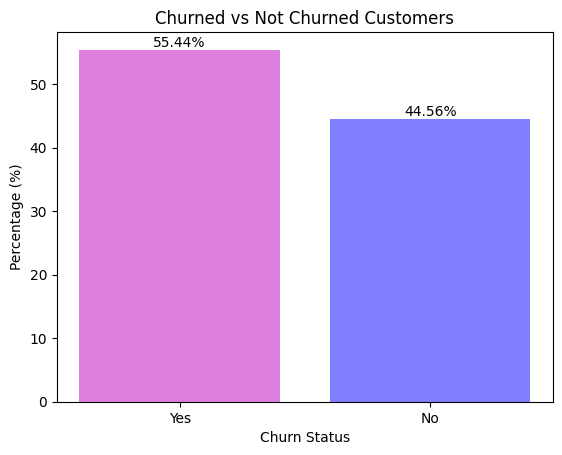

In [133]:
import matplotlib.pyplot as plt

# Count churned and not churned customers
churn_count = df['churn'].value_counts()

# Calculate percentage
churn_percentage = (churn_count / churn_count.sum()) * 100

# Bar plot
plt.bar(churn_percentage.index, churn_percentage.values, color = ["m", "b"], alpha = 0.5)

plt.xlabel('Churn Status')
plt.ylabel('Percentage (%)')
plt.title('Churned vs Not Churned Customers')

# Show percentage on top of each bar
for i, value in enumerate(churn_percentage.values):
    plt.text(i, value + 0.5, f'{value:.2f}%', ha='center')
    
plt.show()

* From the above bar plot we have noticed that from our total customers 55.44% customers have churned and rest 44.56% have not churned.

* 2. what are the average total_spending of churned and non-churned customers ?

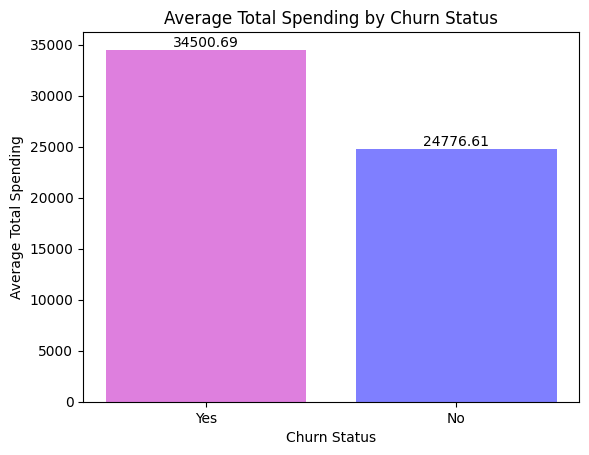

In [134]:
avg_spending = df.groupby('churn')['totalcharges'].mean().reindex(['Yes', 'No'])

plt.bar(avg_spending.index, avg_spending.values, color = ["m", "b"], alpha = 0.5)

plt.xlabel('Churn Status')
plt.ylabel('Average Total Spending')
plt.title('Average Total Spending by Churn Status')

for i, value in enumerate(avg_spending.values):
    plt.text(i, value, f'{value:.2f}', ha='center', va='bottom')

plt.show()

* From the above bar plot we have noticed that the average total spending of churned customer is 34500.69 and average total spending of not churned customer is 24776.61.

* 3.Calculate Quarterly churned and their total spending ?

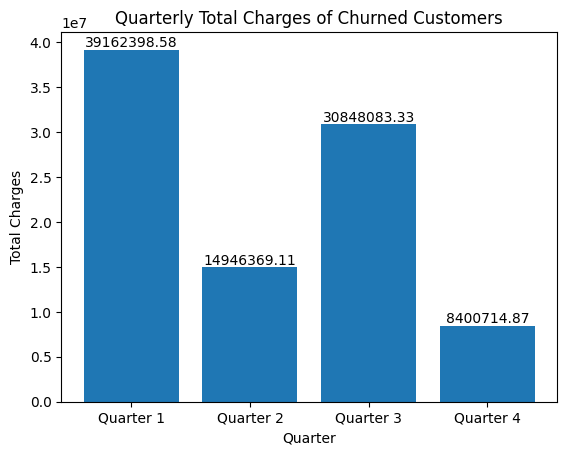

In [135]:
import matplotlib.pyplot as plt

# Filter churned customers and calculate total charges by quarter
quarterly_charges = (
    df[df['churn'] == 'Yes']
    .groupby('quarter')['totalcharges']
    .sum()
)

# Keep quarters in correct order
quarterly_charges = quarterly_charges.reindex(['Quarter 1', 'Quarter 2', 'Quarter 3', 'Quarter 4'])

# Bar plot
plt.bar(quarterly_charges.index, quarterly_charges.values)

plt.xlabel('Quarter')
plt.ylabel('Total Charges')
plt.title('Quarterly Total Charges of Churned Customers')

# Show values on bars
for i, value in enumerate(quarterly_charges.values):
    plt.text(i, value, f'{value:.2f}', ha='center', va='bottom')

plt.show()

* From the above bar plot we can see that **Quarter 1** has the highest total spending from churned customers (about 39.16M), followed by Quarter 3 (about 30.85M). Quarter 2 (about 14.95M) and Quarter 4 (about 8.40M) are much lower.

* 4.Total spent of churned and non-churned customers ?


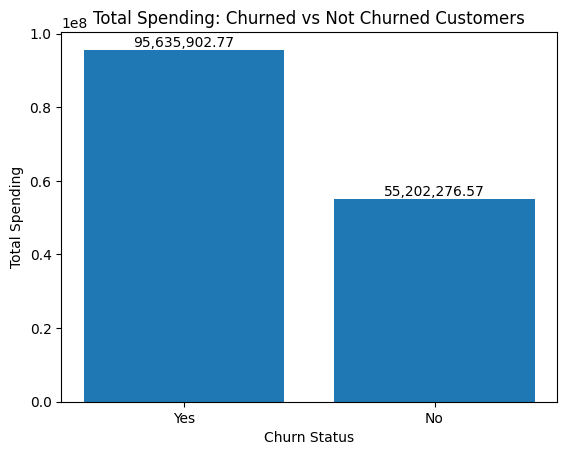

In [136]:
import matplotlib.pyplot as plt

# Calculate total spending by churn status
total_spending = df.groupby('churn')['totalcharges'].sum()

# Keep Yes and No order
total_spending = total_spending.reindex(['Yes', 'No'])

# Bar plot
plt.bar(total_spending.index, total_spending.values)

plt.xlabel('Churn Status')
plt.ylabel('Total Spending')
plt.title('Total Spending: Churned vs Not Churned Customers')

# Show values on bars
for i, value in enumerate(total_spending.values):
    plt.text(i, value, f'{value:,.2f}', ha='center', va='bottom')

plt.show()

* From the above Bar plot we have noticed that the total spending of churned customer is 95635902.76 and total spending of not churned customed is 55202276.56

* 5.Total number of customers has churned and non-churned ?

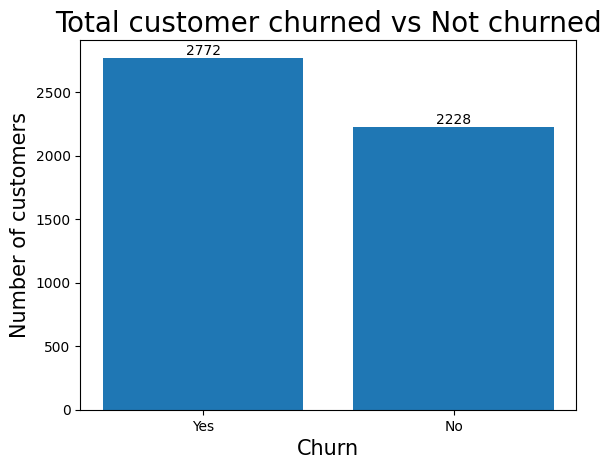

In [137]:
#Calculate  total churn and not churn customers by churn status
total_churn = df.groupby('churn')['customerid'].count().reindex(['Yes', 'No'])

#Bar plot
plt.bar(total_churn.index, total_churn.values)

plt.title("Total customer churned vs Not churned", fontsize = 20)
plt.xlabel("Churn", fontsize = 15)
plt.ylabel("Number of customers", fontsize = 15)

#Show values on bars
for i,value in enumerate(total_churn.values):
    plt.text(i, value, f'{value}', ha = 'center', va = 'bottom')

plt.show()

* From the above bar plot we have noticed that from our total 5000 customers there are 2772 customers churned and 2228 customers not churned

* 6.Average Tenuremonths of churned non-churned customers ?

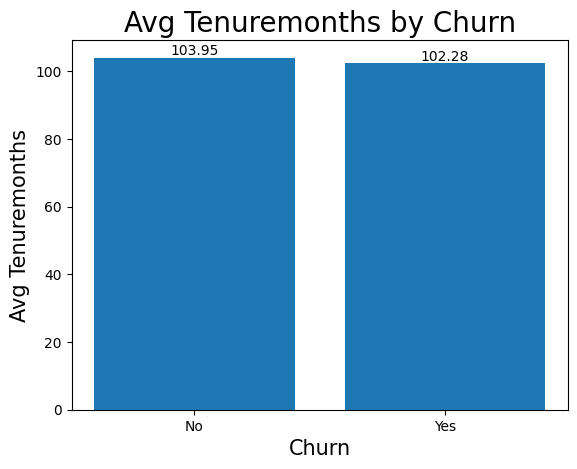

In [138]:
#Calculate average_tenuremonths of churned and non-churned customers by churn status
average_tenuremonths = df.groupby('churn')['tenuremonths'].mean()

#Bar plot
plt.bar(average_tenuremonths.index, average_tenuremonths.values)

plt.xlabel("Churn", fontsize = 15)
plt.ylabel("Avg Tenuremonths", fontsize = 15)
plt.title("Avg Tenuremonths by Churn", fontsize = 20)



#Show values on bar
for i,value in enumerate(average_tenuremonths.values):
    plt.text(i, value, f'{value:.2f}', ha = 'center', va = 'bottom')

plt.show()
 

* We can see from the above bar plot that there are no effect by the tenuremonths on churn status

* 7.Calculate churn group by year ?

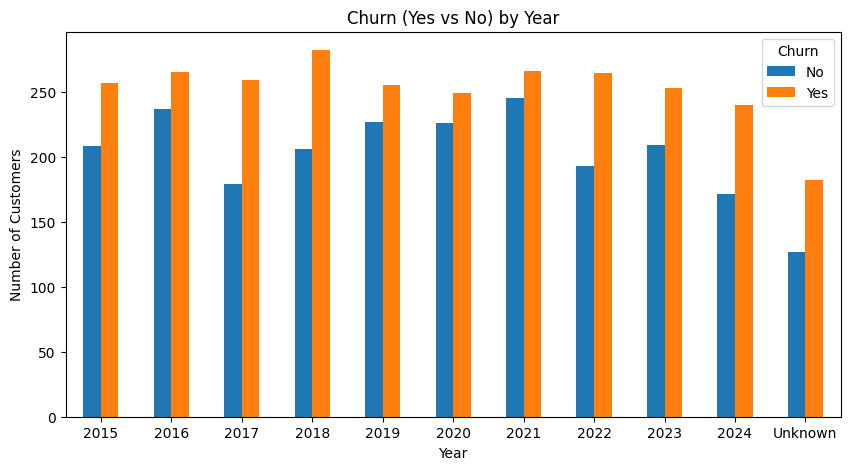

In [139]:
churn_by_year = pd.crosstab(df['year'], df['churn'])

churn_by_year.plot(kind='bar', figsize=(10, 5))

plt.xlabel('Year')
plt.ylabel('Number of Customers')
plt.title('Churn (Yes vs No) by Year')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

* From the above chart we can see that in every year (2015-2024) more customers churned than stayed. Churned customers stay in a steady range of roughly 240-280 per year (highest in 2018), so there is no clear upward or downward trend over time.

* 8. Customers grouped by Internetservice ?

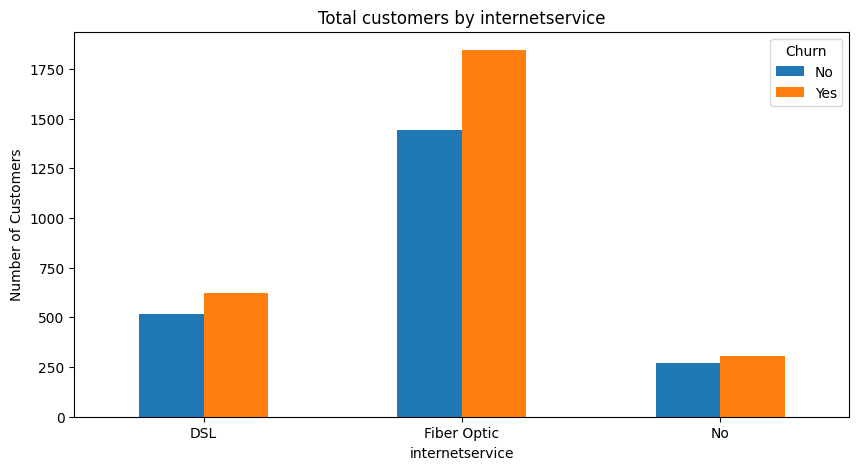

In [140]:
churn_by_internetservice = pd.crosstab(df['internetservice'], df['churn'])

churn_by_internetservice.plot(kind='bar', figsize=(10, 5))

plt.xlabel('internetservice')
plt.ylabel('Number of Customers')
plt.title('Total customers by internetservice')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

* From the above chart we can see that Fiber Optic is the largest customer group (roughly 3,300 customers), followed by DSL (roughly 1,150) and customers with no internet service (roughly 575). In all three groups churned customers outnumber active ones, and the churn share is similar across groups (roughly 53-56%), so internet service type alone does not clearly separate churners from non-churners.

# 9. Key Findings

* **Overall churn:** 2,772 of 5,000 customers (**55.44%**) churned and 2,228 (44.56%) did not.
* **Spending:** churned customers account for about **63%** of total charges (95.64M vs 55.20M). Their average total spending is also higher (**34,500.69** vs 24,776.61, about 39% more), meaning the business lost some of its higher-value customers.
* **Timing:** among churned customers, **Quarter 1** carries the most total spending (about 39.16M), followed by **Quarter 3** (about 30.85M); Quarter 4 is lowest (about 8.40M).
* **Tenure:** average tenure is almost the same for churned (102.28 months) and non-churned (103.95 months) customers, so tenure alone does not explain churn here.
* **Year:** churned customers outnumber active ones in every signup year from 2015 to 2024, with no clear trend.
* **Internet service:** Fiber Optic is the largest group, and churn is high across all service types (roughly 53-56%), so service type alone is not a strong separator.

# 10. Business Recommendations

* Treat the churn rate of more than 50% as the top priority and investigate the causes with additional fields (reasons for leaving, satisfaction, support history).
* Focus retention offers on higher-spending customers, since they make up most of the churned revenue.
* Plan retention campaigns ahead of Quarter 1 and Quarter 3, when churned spending is highest.
* Since tenure and internet service type show little difference between churned and active customers, look at other factors next (contract type, payment method, support calls, satisfaction score).

# 11. Assumptions and Limitations

* Missing `Churn` values were filled as **Yes** when `SatisfactionScore` was below 5 and **No** otherwise. This is an assumption and affects the churn rate.
* Missing ages were filled with the previous valid value (forward fill). Missing tenure, monthly charges and total charges were derived from each other where possible, otherwise filled with the group median by age group.
* Rows with missing or unreadable signup dates were kept and labelled **Unknown** for year, month and quarter.
* This is descriptive analysis (EDA). No predictive model was built, and the findings show association, not cause.

# 12. Conclusion

More than half of the customers in this dataset churned. Churned customers carry a large share of total revenue, and churn is spread across years and internet service types, so the next step is to study further drivers such as contract type, payment method, support calls and satisfaction to understand why customers leave.